# Churn EDA — verified analysis

Narrative version of the analysis. Every number quoted here is recomputed by the `eda/` modules; `EDA_FINDINGS.md` is checked against the same code by `scripts/verify_findings.py`.

Label: no purchase in the 90 days before 2026-08-01. Zero-activity customers are churned.

In [1]:
import sys
from pathlib import Path
import os

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from eda.load import load_customers, load_transactions, load_monthly_agg
from eda.profile import profile_schema, profile_missingness, count_zero_activity_customers, profile_distribution, count_outliers
from eda.hypotheses import run_all_hypotheses, derive_pre_window_drivers
from eda.leakage_checks import AS_OF, eligible_customers, flag_label_circular_drivers, trailing_window_diagnostics, check_no_post_as_of_rows_used
from eda.time_checks import monthly_volume_trend, trend_summary, compare_row_level_vs_monthly_agg

ARTIFACTS = Path("outputs/artifacts")
ARTIFACTS.mkdir(parents=True, exist_ok=True)
customers = load_customers()
transactions = load_transactions()
monthly_agg = load_monthly_agg()
print("loaded", len(customers), "customers,", len(transactions), "transaction rows,", len(monthly_agg), "monthly rows")

loaded 1500 customers, 11742 transaction rows, 8086 monthly rows


## 1. Schema, missingness and zero-activity customers

In [2]:
for name, df in [("customers", customers), ("transactions", transactions), ("monthly_agg", monthly_agg)]:
    print(name, profile_schema(df)["n_rows"], "rows; nulls:", {k: v for k, v in profile_missingness(df).items() if v})
zero = count_zero_activity_customers(customers, transactions)
print("zero-activity customers:", zero)
print("their churn status:", customers.loc[~customers.customer_id.isin(transactions.customer_id), "churned"].value_counts().to_dict())

customers 1500 rows; nulls: {}
transactions 11742 rows; nulls: {}
monthly_agg 8086 rows; nulls: {}
zero-activity customers: 81
their churn status: {1: 81}


Zero-activity customers have no transaction rows, which is not the same as missing data: no column is null for them.
All of them are churned, which is the label restated, so they are not used as a feature.

## 2. Churn rate, class balance and the signup-eligibility artifact

In [3]:
churn_rate = customers["churned"].mean()
print(f"overall churn rate: {churn_rate:.4f} ({customers.churned.sum()} of {len(customers)})")
print(f"always-not-churned accuracy: {1 - churn_rate:.4f}")
eligible = eligible_customers(customers, AS_OF)
late = customers[customers.signup_date >= AS_OF - pd.Timedelta(days=90)]
print(f"eligible (signed up before window): {len(eligible)}, churn rate {eligible.churned.mean():.4f}")
print(f"signed up inside window: {len(late)}, churn rate {late.churned.mean():.2f}  <- eligibility artifact")

overall churn rate: 0.1347 (202 of 1500)
always-not-churned accuracy: 0.8653
eligible (signed up before window): 1400, churn rate 0.1107
signed up inside window: 100, churn rate 0.47  <- eligibility artifact


Accuracy is misleading here: predicting "not churned" for everyone already scores about 0.87.
Customers who signed up inside the window are labelled churned before they could buy, so driver testing uses the eligible population.

## 3. Distribution, skew and outliers of transaction amount

{'n': 11742, 'mean': 49.72, 'median': 33.82, 'skew': 6.11, 'skew_direction': 'right', 'min': 3.0, 'max': 1684.21}
{'rule': 'iqr x1.5', 'bound_low': -46.181250000000006, 'bound_high': 125.92875000000001, 'n_outliers': 783}


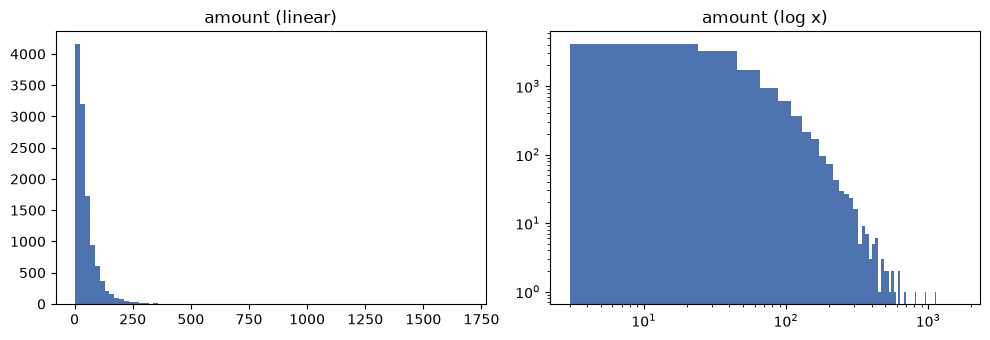

In [4]:
dist = profile_distribution(transactions["amount"])
print({k: round(v, 2) if isinstance(v, float) else v for k, v in dist.items()})
outliers = count_outliers(transactions["amount"])
print(outliers)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(transactions["amount"], bins=80, color="#4C72B0")
ax[0].set_title("amount (linear)")
ax[1].hist(transactions["amount"], bins=80, color="#4C72B0", log=True)
ax[1].set_xscale("log")
ax[1].set_title("amount (log x)")
fig.tight_layout()
fig.savefig(ARTIFACTS / "amount_distribution.png", dpi=110)
plt.show()

Amount is strongly right-skewed (mean well above median), so monetary summaries use median and IQR.
The Tukey-fence outliers are kept in the data and flagged as a data issue, not removed.

## 4. Candidate churn drivers: hypothesis tests on the eligible population

In [5]:
results = pd.DataFrame(run_all_hypotheses(customers, transactions))
pd.set_option("display.width", 200)
print(results[["driver", "test", "n", "statistic", "p_value", "effect_size_or_magnitude", "effect_metric", "higher_group"]].to_string(index=False))
results.to_csv(ARTIFACTS / "hypothesis_results.csv", index=False)

              driver                            test    n    statistic  p_value  effect_size_or_magnitude                                     effect_metric higher_group
 acquisition_channel chi-square test of independence 1400     6.374254 0.094756                  0.067476                                        Cramer's V          NaN
              region chi-square test of independence 1400     6.585612 0.086347                  0.068586                                        Cramer's V          NaN
pre_window_txn_count      Mann-Whitney U (two-sided) 1400 85979.000000 0.026267                 -0.108910 rank-biserial r (positive = churned tends higher)  not_churned
    pre_window_spend      Mann-Whitney U (two-sided) 1400 85665.000000 0.022311                 -0.112165 rank-biserial r (positive = churned tends higher)  not_churned


- **acquisition_channel** and **region**: chi-square tests of independence against churn. Both are **null** at alpha 0.05 (p about 0.09), so the apparent channel and region gaps are not reported as drivers.
- **pre_window_txn_count** and **pre_window_spend**: Mann-Whitney U, because both are right-skewed with many zeros, so a t-test's normality assumption fails. Both are significant but small (rank-biserial about -0.11). Churned customers have slightly less pre-window activity.
- Excluded from testing as drivers: **days_since_last_txn** and **trailing_90d_spend** (see section 5).

## 5. Leakage check: trailing-window variables

In [6]:
flags = flag_label_circular_drivers(["acquisition_channel", "region", "tenure_days", "pre_window_txn_count", "pre_window_spend", "days_since_last_txn", "trailing_90d_spend"])
print("flagged:", list(flags["flagged"]))
for name, reason in flags["flagged"].items():
    print(" -", name, ":", reason)
print("not flagged:", flags["not_flagged"])
diag = trailing_window_diagnostics(customers, transactions)
print({k: round(v, 4) for k, v in diag.items()})

flagged: ['days_since_last_txn', 'trailing_90d_spend']
 - days_since_last_txn : computed over all history before as-of, which overlaps the label's own trailing 90-day window; circular with the label
 - trailing_90d_spend : computed over the last 90 days before as-of, which overlaps the label's own trailing 90-day window; circular with the label
not flagged: ['acquisition_channel', 'region', 'tenure_days', 'pre_window_txn_count', 'pre_window_spend']
{'days_since_last_txn_min_churned': 91.0, 'days_since_last_txn_max_not_churned': 90.0, 'days_since_last_txn_mwu_p': 0.0, 'days_since_last_txn_n_nonnull': 1419, 'trailing_90d_spend_max_churned': 0.0, 'trailing_90d_spend_min_not_churned': 0.0}


`days_since_last_txn` and `trailing_90d_spend` are computed over the same 90-day window as the label. Churned customers have at least 91 days since last transaction and zero trailing spend, so their separation is circular: it restates the label rather than predicting it.
They are excluded from modelling. Stage 0 read them as the strongest predictor; that reading is rejected.

## 6. Monthly transaction-volume trend (non-stationarity)

{'column': 'txn_count', 'n_months': 30, 'first_month': '2024-02-01', 'last_month': '2026-07-01', 'slope_per_month': 41.023, 'spearman_rho': 0.998, 'spearman_p': 0.0, 'direction': 'increasing'}


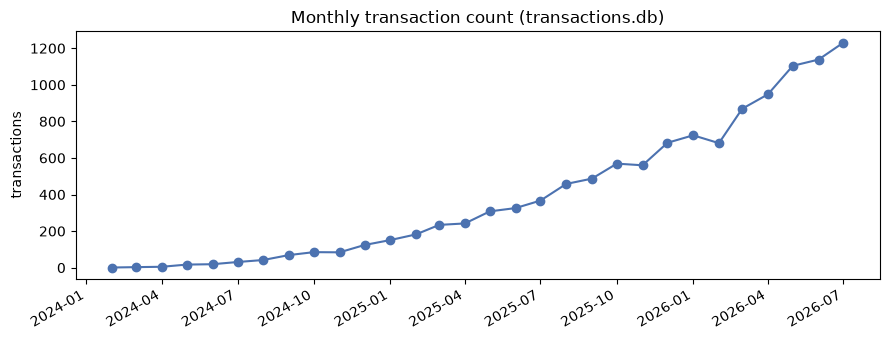

In [7]:
trend = monthly_volume_trend(transactions)
summary = trend_summary(trend, "txn_count")
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in summary.items()})
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(trend["month"], trend["txn_count"], marker="o", color="#4C72B0")
ax.set_title("Monthly transaction count (transactions.db)")
ax.set_ylabel("transactions")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(ARTIFACTS / "monthly_volume_trend.png", dpi=110)
plt.show()

Monthly volume rises steadily (Spearman rho close to 1). A random train/test split would put later behaviour into training, so validation must be time-based.

## 7. Multi-source comparison: row-level table vs monthly parquet

months compared: 30 | months with any disagreement: 1
     month  db_txn_count  pq_txn_count  db_total_amount  pq_total_amount  customer_months_db_only  customer_months_pq_only  customer_months_txn_count_mismatch  customer_months_total_amount_mismatch  txn_count_diff  total_amount_diff
2026-07-01          1231         994.0         62084.62         50116.67                      102                        0                                 110                                    110           237.0           11967.95


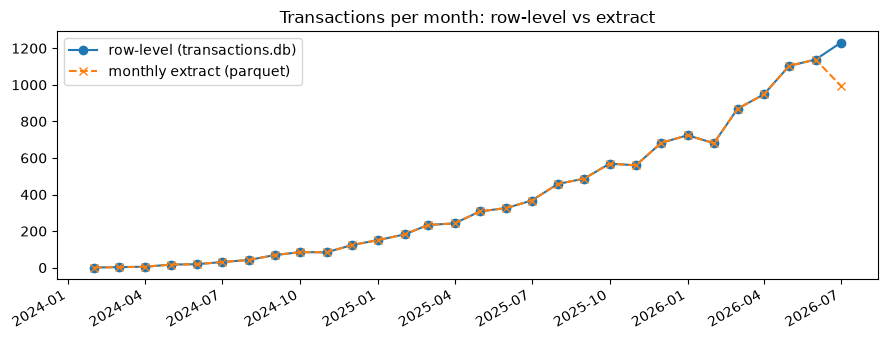

In [8]:
comparison = compare_row_level_vs_monthly_agg(transactions, monthly_agg)
disagree = comparison[(comparison.txn_count_diff != 0) | (comparison.customer_months_db_only > 0) | (comparison.customer_months_pq_only > 0) | (comparison.customer_months_total_amount_mismatch > 0)]
print("months compared:", len(comparison), "| months with any disagreement:", len(disagree))
print(disagree.to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(comparison["month"], comparison["db_txn_count"], marker="o", label="row-level (transactions.db)")
ax.plot(comparison["month"], comparison["pq_txn_count"], marker="x", linestyle="--", label="monthly extract (parquet)")
ax.set_title("Transactions per month: row-level vs extract")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(ARTIFACTS / "multi_source_comparison.png", dpi=110)
plt.show()

Every month matches exactly except **2026-07**. The parquet extract has far fewer July rows than the row-level table, and about 100 customer-months appear only in the row-level table. The extract's latest month is incomplete; use the row-level table for July until that's fixed (see DATA_ISSUES.md).

## 8. Leakage guard and closing recommendation

In [9]:
print(check_no_post_as_of_rows_used(transactions, str(AS_OF.date())))

{'passed': True, 'n_post_as_of_rows_in_source': 0, 'note': 'rows at/after 2026-08-01 present in the frame used for computation: 0'}


**Recommendation:** regularized, class-weighted logistic regression on the eligible population, using only pre-window features (transaction count, spend, and the categorical drivers). Validate out-of-time, and report PR-AUC, precision/recall on churners and top-decile lift, not accuracy. Gradient-boosted trees are not the top pick: with about 155 churned customers and weak usable signal they would overfit and lose interpretability.

Full reasoning, exclusions and caveats are in `MODEL_RECOMMENDATION.md`. All numbers are checked by `scripts/verify_findings.py`.